<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and source](README.md)

# 01 · How much reported portfolio weight sits in the largest holdings?

A fund can have many holdings while a relatively small number account for much of its reported weight. We will compare **FTCS** and **AIRR**, keeping the fund ticker separate from constituent identifiers, and inspect how the answer changes when the top-five cutoff becomes top ten.

This notebook reads **current public First Trust holdings through the real worker**. It is descriptive, not a recommendation or a comparison of expected returns or risk. The funds have different mandates; a difference in concentration does not establish which is preferable. No synthetic data replace an unavailable source.

## Choose the rank cutoff

`TOP_N` counts holding **lines**, not necessarily unique companies or securities. Values from 1 to 20 are supported. The requested funds are fixed at FTCS and AIRR; only the partition selector is sent to the remote scan. All ranking and aggregation happen after materialization.

Change only **5 → 10 lines** in the final experiment. Predict that cumulative reported weight cannot decrease, while the full source inventory stays unchanged if First Trust publishes no update between runs. Restart the kernel and Run All after editing.

In [1]:
TOP_N = 5  # Integer 1–20 holding lines per fund; experiment: 10

In [2]:
import hashlib
import os
import tempfile
from datetime import datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert type(TOP_N) is int and 1 <= TOP_N <= 20
# The worker caches its catalog for 24h under TMPDIR; use an isolated cache for this acquisition.
previous_tmpdir=os.environ.get("TMPDIR")
worker_cache=tempfile.TemporaryDirectory(prefix="firsttrust-notebook-")
os.environ["TMPDIR"]=worker_cache.name
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: First Trust current holdings · page dates shown in diagnostics · retrieved {retrieved_at[:10]} UTC · reported percent points",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.96));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-first-trust/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-first-trust/notebooks/pyproject.toml.

## Attach the native release and select only two partitions

The literal pinned `github-auto` location downloads the platform binary, checks its SHA-256 and caches it. The surrounding worker checkout is unnecessary. The notebook isolates the worker's 24-hour catalog cache in a fresh temporary directory; holdings pages themselves are fetched live.

The source is First Trust's [FTCS holdings page](https://www.ftportfolios.com/retail/etf/EtfHoldings.aspx?Ticker=FTCS) and [AIRR holdings page](https://www.ftportfolios.com/retail/etf/EtfHoldings.aspx?Ticker=AIRR). The `fund_ticker` filter selects those two fund partitions. An unfiltered holdings scan can visit the full catalog, so it is not appropriate for this bounded comparison.

Release v0.4.0 honors the fund partition selector but has a known limitation with other pushed holdings filters. This notebook sends **only the fund selector** to the worker and applies every analytical filter to its local materialized table.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'firsttrust' AS ft (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-etf-first-trust@v0.4.0'
);

,Success


In [4]:
request_started=datetime.now(timezone.utc).isoformat()

In [5]:
%%sql
CREATE TABLE holdings_source AS
SELECT * FROM ft.main.holdings WHERE fund_ticker IN ('FTCS','AIRR');

,Count


In [6]:
retrieved_at=datetime.now(timezone.utc).isoformat()

## Establish dates, coverage and units before ranking

`as_of_date` is the page's published holdings date, not our retrieval timestamp. It is a calendar DATE with no timezone. Holdings are current-only: there is no historical request argument and the two responses are not an atomic snapshot. A repeat run can therefore change the data as well as the chosen cutoff.

`weight_percent` is already in percent points: **2.5 means 2.5%, not 0.025**. We preserve the reported sum and show its difference from 100 rather than rescaling every fund to 100. Rounding, coverage and nonstandard lines can matter. Missing weights remain unavailable, and no holding identifier is assumed to be a unique row key.

In [7]:
%%sql diagnostics <<
WITH requested(fund_ticker) AS (VALUES ('FTCS'),('AIRR'))
SELECT r.fund_ticker,count(h.fund_ticker) AS holding_lines,
       min(h.as_of_date) AS first_page_date,max(h.as_of_date) AS last_page_date,
       count(DISTINCT h.as_of_date) AS page_dates,
       count(h.weight_percent) AS lines_with_weight,
       count(*) FILTER (WHERE h.fund_ticker IS NOT NULL AND h.weight_percent IS NULL) AS missing_weights,
       count(*) FILTER (WHERE h.weight_percent<0) AS negative_weights,
       sum(h.weight_percent) AS reported_weight_percent,
       sum(h.weight_percent)-100 AS difference_from_100_pp,
       count(*) FILTER (WHERE h.fund_ticker IS NOT NULL AND (h.ticker IS NULL OR h.ticker='')) AS missing_constituent_tickers
FROM requested r LEFT JOIN holdings_source h USING(fund_ticker)
GROUP BY r.fund_ticker ORDER BY r.fund_ticker;

In [8]:
display(diagnostics)
assert diagnostics.holding_lines.gt(0).all(), "Required fund returned no holdings; the worker can return empty on an unavailable or unparsable page. No zero portfolio is inferred."
assert diagnostics.page_dates.eq(1).all(), "Each fund needs one consistent published holdings date."
assert diagnostics.lines_with_weight.ge(TOP_N).all(), "The cutoff exceeds the available weighted holding lines."
assert diagnostics.negative_weights.eq(0).all(), "This cumulative-weight example requires nonnegative reported weights; inspect negative lines before using its interpretation."
prose(f"Retrieved UTC: **{request_started} → {retrieved_at}**. "
      f"The source returned **{int(diagnostics.holding_lines.sum())} lines** across the two requested funds, including "
      f"**{int(diagnostics.missing_weights.sum())} missing weights** and **{int(diagnostics.missing_constituent_tickers.sum())} missing constituent tickers**. "
      "The table keeps those availability counts beside the page dates and reported totals; a missing identifier does not make a holding line disappear.")

,fund_ticker,holding_lines,first_page_date,last_page_date,page_dates,lines_with_weight,missing_weights,negative_weights,reported_weight_percent,difference_from_100_pp,missing_constituent_tickers
0,AIRR,56,2026-11-12,2026-11-12,1,56,0,0,99.95,-0.05,0
1,FTCS,51,2026-11-12,2026-11-12,1,51,0,0,99.99,-0.01,0


Retrieved UTC: **2026-11-14T06:23:22.138996+00:00 → 2026-11-14T06:23:29.985249+00:00**. The source returned **107 lines** across the two requested funds, including **0 missing weights** and **0 missing constituent tickers**. The table keeps those availability counts beside the page dates and reported totals; a missing identifier does not make a holding line disappear.

## Rank reported weights without collapsing holding lines

Rank by descending reported weight. Ties use name, constituent ticker and CUSIP as deterministic secondary labels; identical duplicated lines remain separate. Ties have the same weight, so a cutoff through a tie does not change the top-weight total.

We exclude only missing weights from the rank calculation and retain their count above. The cumulative sum is in reported percent points of the fund, not a renormalized share of the rows that happened to be returned.

In [9]:
%%sql
CREATE TABLE ranked_holdings AS
SELECT *,row_number() OVER (
           PARTITION BY fund_ticker ORDER BY weight_percent DESC,name,ticker,cusip
       ) AS holding_rank
FROM holdings_source WHERE weight_percent IS NOT NULL;
CREATE TABLE cumulative_holdings AS
SELECT *,sum(weight_percent) OVER (
           PARTITION BY fund_ticker ORDER BY holding_rank ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
       ) AS cumulative_weight_percent
FROM ranked_holdings;

,Count


In [10]:
%%sql ranked <<
SELECT * FROM cumulative_holdings ORDER BY fund_ticker,holding_rank;

In [11]:
%%sql top_lines <<
SELECT fund_ticker,holding_rank,name,ticker AS constituent_ticker,weight_percent,cumulative_weight_percent
FROM cumulative_holdings WHERE holding_rank <= {{TOP_N}} ORDER BY fund_ticker,holding_rank;

,fund_ticker,holding_rank,name,constituent_ticker,weight_percent,cumulative_weight_percent
0,AIRR,1,Karman Holdings Inc.,KRMN,3.82,3.82
1,AIRR,2,Nextpower Inc. (Class A),NXT,3.73,7.55
2,AIRR,3,"C.H. Robinson Worldwide, Inc.",CHRW,3.64,11.19
3,AIRR,4,"Herc Holdings, Inc.",HRI,3.57,14.76
4,AIRR,5,"Huntington Ingalls Industries, Inc.",HII,3.49,18.25
5,FTCS,1,Veralto Corporation,VLTO,2.22,2.22
6,FTCS,2,"PPG Industries, Inc.",PPG,2.16,4.38
7,FTCS,3,3M Company,MMM,2.15,6.53
8,FTCS,4,Cincinnati Financial Corporation,CINF,2.13,8.66
9,FTCS,5,"The Home Depot, Inc.",HD,2.13,10.79


Weighted-holdings fingerprint: `7bd8aac56a0dc49749930472f29561ee4f2bdf99a38e7a8fa151878230b8c4e2`. This fingerprint covers the ranked observations, including each page date; the diagnostics separately track any missing-weight lines.

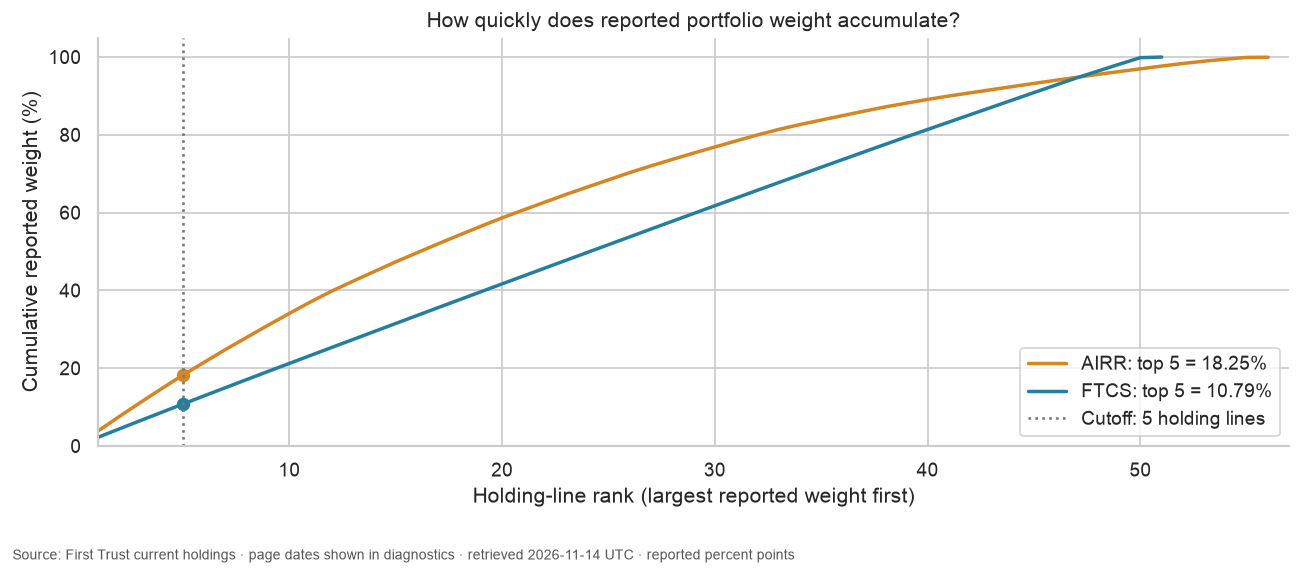

In [12]:
display(top_lines)
assert set(ranked.fund_ticker)=={"FTCS","AIRR"}
for fund,rows in ranked.groupby("fund_ticker"):
    assert rows.holding_rank.tolist()==list(range(1,len(rows)+1))
    assert rows.cumulative_weight_percent.diff().dropna().ge(-1e-10).all()
    assert np.isclose(rows.cumulative_weight_percent.iloc[-1],diagnostics.set_index("fund_ticker").loc[fund,"reported_weight_percent"])
source_hash=hashlib.sha256(ranked[["fund_ticker","as_of_date","weight_percent","ticker","name","cusip","sector","shares_held","market_value"]].to_json(orient="records",date_format="iso").encode()).hexdigest()
prose(f"Weighted-holdings fingerprint: `{source_hash}`. This fingerprint covers the ranked observations, including each page date; the diagnostics separately track any missing-weight lines.")
colors={"FTCS":"#247f9e","AIRR":"#d78520"}
fig,ax=plt.subplots(figsize=(10.5,4.8))
for fund,rows in ranked.groupby("fund_ticker"):
    selected=rows.loc[rows.holding_rank.eq(TOP_N)].iloc[0]
    ax.plot(rows.holding_rank,rows.cumulative_weight_percent,color=colors[fund],label=f"{fund}: top {TOP_N} = {selected.cumulative_weight_percent:.2f}%",linewidth=2)
    ax.scatter([TOP_N],[selected.cumulative_weight_percent],color=colors[fund],s=45)
ax.axvline(TOP_N,color="#777777",linestyle=":",label=f"Cutoff: {TOP_N} holding lines")
ax.set(xlabel="Holding-line rank (largest reported weight first)",ylabel="Cumulative reported weight (%)",xlim=(1,int(ranked.holding_rank.max())+1),ylim=(0,max(100,float(ranked.cumulative_weight_percent.max()))*1.05),title="How quickly does reported portfolio weight accumulate?")
ax.legend(loc="lower right");finish(fig)

## Separate the selected top lines from the reported remainder

The stacked bars add back to each fund's reported, nonmissing weight sum. They do not automatically add to exactly 100%. The remainder is the known weight outside the cutoff, not an estimate for any unavailable rows.

A higher top-line total describes concentration in this particular holdings snapshot. It does not measure issuer overlap between funds, correlations among holdings, future returns or loss risk.

In [13]:
%%sql concentration <<
SELECT fund_ticker,count(*) AS weighted_lines,
       sum(weight_percent) FILTER (WHERE holding_rank <= {{TOP_N}}) AS top_weight_percent,
       sum(weight_percent) FILTER (WHERE holding_rank > {{TOP_N}}) AS remaining_weight_percent,
       sum(weight_percent) AS total_reported_weight_percent
FROM ranked_holdings GROUP BY fund_ticker ORDER BY fund_ticker;

,fund_ticker,weighted_lines,top_weight_percent,remaining_weight_percent,total_reported_weight_percent
0,AIRR,56,18.25,81.7,99.95
1,FTCS,51,10.79,89.2,99.99


**AIRR: 18.25%** in the top 5 lines, with 81.70% in the other reported weighted lines; **FTCS: 10.79%** in the top 5 lines, with 89.20% in the other reported weighted lines. Compare these figures with the source dates and missing-weight counts above before attributing a change to the cutoff alone.

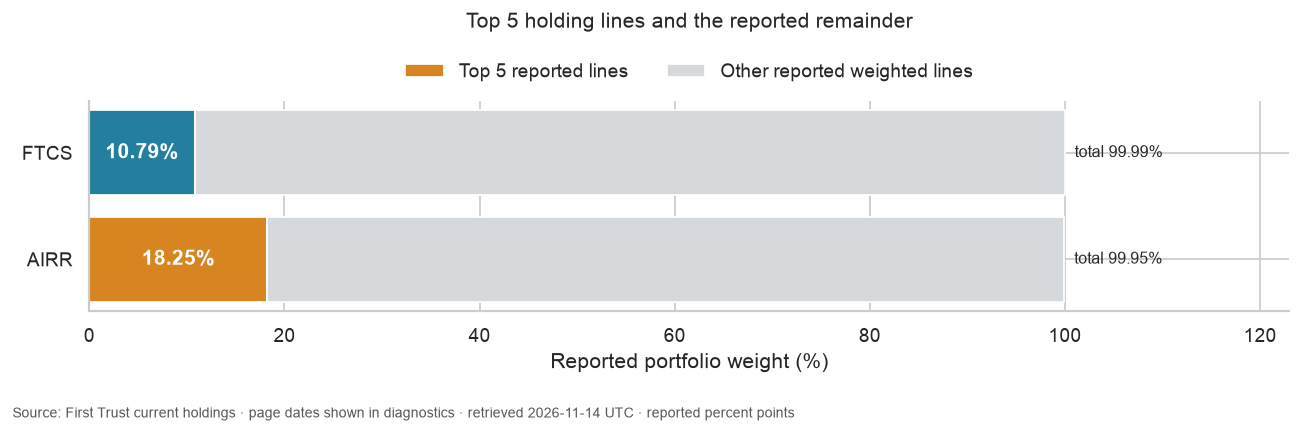

In [14]:
display(concentration)
assert np.allclose(concentration.top_weight_percent+concentration.remaining_weight_percent,concentration.total_reported_weight_percent)
assert concentration.top_weight_percent.ge(0).all()
assert concentration.top_weight_percent.le(concentration.total_reported_weight_percent+1e-10).all()
parts=[f"**{r.fund_ticker}: {r.top_weight_percent:.2f}%** in the top {TOP_N} lines, with {r.remaining_weight_percent:.2f}% in the other reported weighted lines" for r in concentration.itertuples()]
prose("; ".join(parts)+". Compare these figures with the source dates and missing-weight counts above before attributing a change to the cutoff alone.")
fig,ax=plt.subplots(figsize=(10.5,3.6))
ax.barh(concentration.fund_ticker,concentration.top_weight_percent,color=[colors[x] for x in concentration.fund_ticker],label=f"Top {TOP_N} reported lines")
ax.barh(concentration.fund_ticker,concentration.remaining_weight_percent,left=concentration.top_weight_percent,color="#d5d9dc",label="Other reported weighted lines")
for i,row in enumerate(concentration.itertuples()):
    ax.text(row.top_weight_percent/2,i,f"{row.top_weight_percent:.2f}%",ha="center",va="center",color="white",weight="bold")
    ax.text(row.total_reported_weight_percent+1,i,f"total {row.total_reported_weight_percent:.2f}%",va="center",fontsize=9)
ax.set(xlabel="Reported portfolio weight (%)",xlim=(0,max(100,float(concentration.total_reported_weight_percent.max()))*1.23),title=f"Top {TOP_N} holding lines and the reported remainder")
ax.set_title(f"Top {TOP_N} holding lines and the reported remainder",pad=42)
ax.legend(loc="lower center",bbox_to_anchor=(.5,1.01),ncol=2,frameon=False);finish(fig)

## One change to test

Change only **`TOP_N` from `5` to `10`** and execute a separate copy using the [README](README.md). Predict a nondecreasing top-weight total for each fund and a corresponding reduction in the reported remainder. Compare the page dates, weighted-holdings fingerprint and availability counts first; a live source update would mean the experiment changed more than the cutoff.

Restore **5** afterward. The acquisition is current-only, so saved outputs are a dated observation rather than a reusable historical endpoint. An empty worker result cannot distinguish a genuinely empty page from a retrieval/parser failure; the required-source check stops that case instead of plotting a zero portfolio.

In [15]:
con.execute("DETACH ft")
con.close()
if previous_tmpdir is None:os.environ.pop("TMPDIR",None)
else:os.environ["TMPDIR"]=previous_tmpdir
worker_cache.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)